# Jev 입문 튜토리얼 — 오픈 모델 OpenJevX로 *판단하는 AI* 돌려보기

이 노트북은 **API 키 없이**, Colab CPU에서 오픈 가중치 모델 **OpenJevX**를 직접 내려받아 Jev 방식의 판단을 실습합니다.

| 순서 | 내용 |
|---|---|
| 1 | Jev란 무엇인가 (System 1 vs System 2) |
| 2 | OpenJevX 설치하고 불러오기 |
| 3 | 첫 번째 판단 — `noul` (예/아니오) |
| 4 | 규칙 판단 — JSON state 넣기 |
| 5 | 세 가지 질문을 한 번에 — `choice` · `noul` · `score` |
| 6 | 확률과 confidence 읽는 법 |
| 7 | 알아둘 한계 — 한국어 입력 |
| 8 | 실습: confidence로 자동 처리 / 사람 검토 나누기 |
| 부록 | TypeSafe AI 공식 API로 쓰는 방식 (간단 소개) |


## 1. Jev란 무엇인가

### System 1과 System 2
심리학자 대니얼 카너먼은 사람의 사고를 두 가지로 나눴습니다.

- **System 1**: 빠르고 자동적. 얼굴 알아보기, "2×2" 답하기, 문의를 보고 담당 부서 떠올리기
- **System 2**: 느리고 의도적. 17×24 암산, 계약서 검토, 다단계 추론

지금의 AI 시스템은 단어 하나면 되는 분류도 LLM(문장을 한 토큰씩 *생성*하는 기계)에 맡깁니다. 빠른 판단을 느린 생성 기계로 흉내 내는 셈이죠.

### Jev = System One Model
TypeSafe AI가 2026년 9월 공개한 **Jev**는 *판단 전용* 모델입니다. 한 문장으로 줄이면:

> **정리되지 않은 입력을 받아, 타입이 정해진 확률적 판단을 돌려준다.**

이름은 19세기에 논리 기계(logic piano)를 만든 경제학자 윌리엄 스탠리 **제번스(Jevons)** 에서 왔습니다.

| | System One Model (Jev) | 일반 LLM | Reasoning LLM |
|---|---|---|---|
| 하는 일 | 판단 | 생성 | 추론 |
| 출력 | 구조화된 값 + 확률 | 문자열 | 문자열 + 생각 과정 |
| 속도 | 빠름 | 보통 | 느림 |
| 어울리는 문제 | 후보가 정해진 반복 판단 | 글쓰기·요약·대화 | 수학·코드·다단계 문제 |

### 호출 구조: State + Questions
- **State**: 판단할 대상 (문자열 또는 JSON)
- **Questions**: 그 State에 던지는 *이름 붙은* 질문들. 질문 형태는 딱 세 가지입니다.

| 질문 | 묻는 것 | 예 | 핵심 값 |
|---|---|---|---|
| `choice` | 여러 후보 중 어느 것? | 어느 부서로 보낼까 | `choice` (고른 후보) |
| `noul` | 예 / 아니오? | 환불을 요구하는가 | `noul` (예일 확률) |
| `score` | 어느 정도? | 얼마나 급한가 | `score` (단계의 기대값) |

모든 답에는 **`probabilities`(후보별 확률)와 `confidence`** 가 함께 옵니다.
Jev는 문장을 생성하지도, 대화하지도, *후보에 없는 답을 만들지도* 않습니다. 후보를 넷으로 정의하면 반드시 넷 중 하나가 나오므로 코드가 결과를 바로 쓸 수 있습니다.

### 왜 OpenJevX인가
TypeSafe의 Jev 자체는 공개되지 않은 **API 전용** 모델입니다(Early Access, API 키 필요, 부록 참고).
이 노트북에서 쓰는 **[OpenJevX](https://huggingface.co/muthuishere/openjevx)** 는 같은 요청 형식(state + questions → typed answers)을 따르는 **오픈 가중치 판단 모델**입니다.

- 약 0.4B 파라미터, ModernBERT 계열 인코더 + 판단 헤드 (*비생성형*, 토큰을 하나씩 만들지 않음)
- 8비트 ONNX 파일(약 600MB)이라 **GPU 없이 CPU에서** 동작
- Apache-2.0 라이선스. TypeSafe AI의 공식 제품이 아닌 **커뮤니티(서드파티) 모델**이라 점수는 공식 Jev와 다를 수 있습니다

## 2. OpenJevX 설치하고 불러오기

필요한 것은 ONNX Runtime과 토크나이저뿐입니다. 런타임 유형은 기본 **CPU**로 충분합니다.

`huggingface_hub`와 `tokenizers`는 Colab에 이미 들어 있으니 **`onnxruntime`만 설치**합니다.
`huggingface_hub`까지 `-U`로 올리면 Colab에 깔린 `datasets`와 버전이 맞지 않는다는 경고가 뜹니다.

In [2]:
# onnxruntime만 최신으로 올립니다 (1.29 이상이어야 8비트 가중치로 빠르게 동작)
# huggingface_hub·tokenizers는 Colab에 이미 설치된 버전을 그대로 사용합니다
!pip install -q -U onnxruntime

모델 저장소에 들어 있는 단일 파일 `openjevx.py`(약 130줄)를 받아 불러옵니다.
`OpenJevX()`를 처음 만들 때 모델 파일(약 600MB)을 한 번 내려받습니다. 1~2분 정도 걸립니다.

> HF_TOKEN 관련 경고가 떠도 무시해도 됩니다. 공개 모델이라 토큰 없이 받아집니다.

In [2]:
import importlib.util
from huggingface_hub import hf_hub_download

path = hf_hub_download("muthuishere/openjevx", "openjevx.py")
spec = importlib.util.spec_from_file_location("openjevx", path)
openjevx = importlib.util.module_from_spec(spec)
spec.loader.exec_module(openjevx)

jev = openjevx.OpenJevX()   # openjevx.w8.onnx + tokenizer.json + config.json 다운로드
print("OpenJevX 준비 완료")

c:\Users\Public\miniconda3\envs\jev_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


OpenJevX 준비 완료


In [3]:
print("Jev:", "jev" in globals())
print("Reviews:", "reviews" in globals())
print("Labels:", "labels" in globals())

Jev: True
Reviews: False
Labels: False


In [4]:
labels = {
    "positive": "긍정",
    "negative": "부정",
    "neutral": "중립"
}

print("감성 라벨 준비 완료")

감성 라벨 준비 완료


In [2]:

# 한국어 혼합 감성 리뷰 분류 프로젝트
# 긍정, 부정, 중립 감성 판단

review = "음식은 맛있었지만 서비스가 너무 느렸어요."

questions = {
    "sentiment": {
        "type": "choice",
        "instructions": "다음 한국어 리뷰의 전체적인 감성을 판단하세요.",
        "criteria": {
            "positive": "긍정적인 평가",
            "negative": "부정적인 평가",
            "neutral": "긍정과 부정이 혼합된 평가 또는 중립적인 평가"
        }
    }
}

result = jev.decide(review, questions)

answer = result["answers"]["sentiment"]

labels = {
    "positive": "긍정",
    "negative": "부정",
    "neutral": "중립"
}

print("===== 한국어 리뷰 감성 분석 결과 =====")
print("리뷰:", review)
print("감성 분류:", labels.get(answer["choice"], answer["choice"]))
print("신뢰도:", round(answer["confidence"], 3))
print("감성별 확률:")

for label, probability in answer["probabilities"].items():
    print(labels.get(label, label), ":", round(probability, 3))


===== 한국어 리뷰 감성 분석 결과 =====
리뷰: 음식은 맛있었지만 서비스가 너무 느렸어요.
감성 분류: 중립
신뢰도: 0.504
감성별 확률:
긍정 : 0.277
부정 : 0.219
중립 : 0.504


In [ ]:

# 한국어 혼합 감성 리뷰 다중 분석
reviews = [
 
    "음식은 맛있었지만 서비스가 너무 느렸어요.",
    "가격은 비싸지만 품질은 정말 좋아요.",
    "배송은 빨랐지만 제품이 파손되어 있었어요.",
    "직원은 친절했지만 매장이 너무 시끄러웠어요.",
    "디자인은 예쁘지만 사용하기 불편해요.",
    "맛도 좋고 서비스도 정말 만족스러웠어요.",
    "가격도 비싸고 품질도 좋지 않았어요.",
    "배송은 느렸지만 포장이 아주 꼼꼼했어요.",
    "시설은 깨끗했지만 위치가 너무 멀었어요.",
    "기대보다 별로였지만 직원들은 친절했어요."
]

results = []

for i, review in enumerate(reviews, start=1):
    result = jev.decide(review, questions)
    answer = result["answers"]["sentiment"]

    sentiment = labels.get(
        answer["choice"], answer["choice"]
    )

    confidence = round(answer["confidence"], 3)

    results.append({
        "번호": i,
        "리뷰": review,
        "감성": sentiment,
        "신뢰도": confidence
    })

    print(f"{i}. {review}")
    print(f"   감성: {sentiment}")
    print(f"   신뢰도: {confidence}")
    print("-" * 40)


1. 음식은 맛있었지만 서비스가 너무 느렸어요.
   감성: 중립
   신뢰도: 0.504
----------------------------------------
2. 가격은 비싸지만 품질은 정말 좋아요.
   감성: 긍정
   신뢰도: 0.449
----------------------------------------
3. 배송은 빨랐지만 제품이 파손되어 있었어요.
   감성: 긍정
   신뢰도: 0.364
----------------------------------------
4. 직원은 친절했지만 매장이 너무 시끄러웠어요.
   감성: 긍정
   신뢰도: 0.375
----------------------------------------
5. 디자인은 예쁘지만 사용하기 불편해요.
   감성: 중립
   신뢰도: 0.371
----------------------------------------
6. 맛도 좋고 서비스도 정말 만족스러웠어요.
   감성: 중립
   신뢰도: 0.42
----------------------------------------
7. 가격도 비싸고 품질도 좋지 않았어요.
   감성: 긍정
   신뢰도: 0.371
----------------------------------------
8. 배송은 느렸지만 포장이 아주 꼼꼼했어요.
   감성: 중립
   신뢰도: 0.38
----------------------------------------
9. 시설은 깨끗했지만 위치가 너무 멀었어요.
   감성: 중립
   신뢰도: 0.366
----------------------------------------
10. 기대보다 별로였지만 직원들은 친절했어요.
   감성: 중립
   신뢰도: 0.365
----------------------------------------


In [6]:

# 한국어 혼합 감성 리뷰 판단 기준 비교

#import pandas as pd

comparison_questions = {
    "overall": {
        "type": "choice",
        "instructions": "리뷰 전체의 감성을 판단하세요.",
        "criteria": {
            "positive": "전체적으로 긍정적인 평가",
            "negative": "전체적으로 부정적인 평가",
            "neutral": "긍정과 부정이 비슷하거나 중립적인 평가"
        }
    },
    "final": {
        "type": "choice",
        "instructions": "리뷰의 마지막 평가를 중심으로 감성을 판단하세요.",
        "criteria": {
            "positive": "마지막 평가가 긍정적임",
            "negative": "마지막 평가가 부정적임",
            "neutral": "마지막 평가가 중립적이거나 불분명함"
        }
    }
}

comparison_results = []

for i, review in enumerate(reviews, start=1):
    result = jev.decide(review, comparison_questions)

    overall = result["answers"]["overall"]["choice"]
    final = result["answers"]["final"]["choice"]

    comparison_results.append({
        "번호": i,
        "리뷰": review,
        "전체 감성": labels.get(overall, overall),
        "최종 평가": labels.get(final, final),
        "판단 일치": "일치" if overall == final else "불일치"
    })

print("===== 판단 기준 비교 결과 =====")

for item in comparison_results:
    print(item)

total = len(comparison_results)
match_count = sum(
    1 for item in comparison_results
    if item["판단 일치"] == "일치"
)
mismatch_count = total - match_count

print("===== 판단 기준 비교 결과 =====")
print("전체 리뷰 수:", total)
print("일치:", match_count)
print("불일치:", mismatch_count)



===== 판단 기준 비교 결과 =====
{'번호': 1, '리뷰': '음식은 맛있었지만 서비스가 너무 느렸어요.', '전체 감성': '중립', '최종 평가': '중립', '판단 일치': '일치'}
{'번호': 2, '리뷰': '가격은 비싸지만 품질은 정말 좋아요.', '전체 감성': '긍정', '최종 평가': '긍정', '판단 일치': '일치'}
{'번호': 3, '리뷰': '배송은 빨랐지만 제품이 파손되어 있었어요.', '전체 감성': '부정', '최종 평가': '긍정', '판단 일치': '불일치'}
{'번호': 4, '리뷰': '직원은 친절했지만 매장이 너무 시끄러웠어요.', '전체 감성': '긍정', '최종 평가': '긍정', '판단 일치': '일치'}
{'번호': 5, '리뷰': '디자인은 예쁘지만 사용하기 불편해요.', '전체 감성': '중립', '최종 평가': '긍정', '판단 일치': '불일치'}
{'번호': 6, '리뷰': '맛도 좋고 서비스도 정말 만족스러웠어요.', '전체 감성': '중립', '최종 평가': '중립', '판단 일치': '일치'}
{'번호': 7, '리뷰': '가격도 비싸고 품질도 좋지 않았어요.', '전체 감성': '중립', '최종 평가': '긍정', '판단 일치': '불일치'}
{'번호': 8, '리뷰': '배송은 느렸지만 포장이 아주 꼼꼼했어요.', '전체 감성': '중립', '최종 평가': '중립', '판단 일치': '일치'}
{'번호': 9, '리뷰': '시설은 깨끗했지만 위치가 너무 멀었어요.', '전체 감성': '긍정', '최종 평가': '긍정', '판단 일치': '일치'}
{'번호': 10, '리뷰': '기대보다 별로였지만 직원들은 친절했어요.', '전체 감성': '부정', '최종 평가': '긍정', '판단 일치': '불일치'}
===== 판단 기준 비교 결과 =====
전체 리뷰 수: 10
일치: 6
불일치: 4


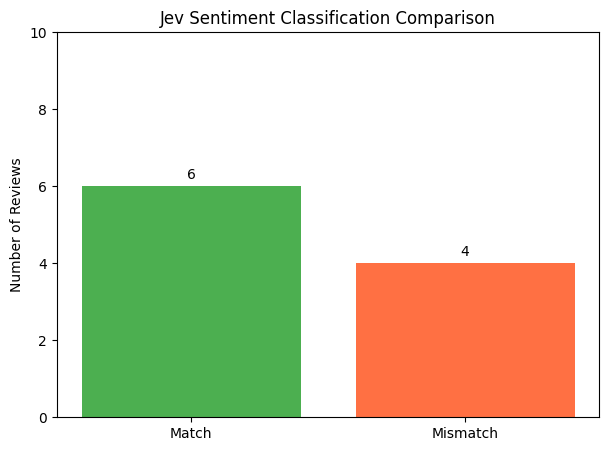

===== 판단 기준 비교 요약 =====
전체 리뷰: 10개
일치: 6개
불일치: 4개
일치율: 60.0%


In [ ]:

# 판단 기준 비교 결과 시각화

import matplotlib.pyplot as plt

match_count = (df["판단 일치"] == "일치").sum()
mismatch_count = (df["판단 일치"] == "불일치").sum()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Match", "Mismatch"],
    [match_count, mismatch_count],
    color=["#4CAF50", "#FF7043"]
)

plt.title("Jev Sentiment Classification Comparison")
plt.ylabel("Number of Reviews")
plt.ylim(0, 10)

for i, value in enumerate([match_count, mismatch_count]):
    plt.text(i, value + 0.2, str(value), ha="center")

plt.show()

print("===== 판단 기준 비교 요약 =====")
print(f"전체 리뷰: {len(df)}개")
print(f"일치: {match_count}개")
print(f"불일치: {mismatch_count}개")
print(f"일치율: {match_count / len(df) * 100:.1f}%")


In [ ]:

# 한국어 리뷰 감성 분류 정확도 비교

# 사람이 직접 설정한 기준 정답
# 혼합 감성 리뷰의 정답은 해석에 따라 달라질 수 있음

true_labels = [
    "중립",
    "긍정",
    "부정",
    "중립",
    "부정",
    "긍정",
    "부정",
    "중립",
    "중립",
    "중립"
]

# 기존 비교 결과에 정답 추가
df["사람 기준 정답"] = true_labels

# 각 판단 기준의 정답 여부 확인
df["전체 감성 정답 여부"] = (
    df["전체 감성"] == df["사람 기준 정답"]
)

df["최종 평가 정답 여부"] = (
    df["최종 평가"] == df["사람 기준 정답"]
)

# 정확도 계산
overall_accuracy = df["전체 감성 정답 여부"].mean() * 100
final_accuracy = df["최종 평가 정답 여부"].mean() * 100

print("===== 감성 분류 정확도 비교 =====")
print(f"전체 감성 기준 정확도: {overall_accuracy:.1f}%")
print(f"최종 평가 기준 정확도: {final_accuracy:.1f}%")

# 결과 표 출력
display(df[[
    "번호",
    "리뷰",
    "사람 기준 정답",
    "전체 감성",
    "최종 평가",
    "전체 감성 정답 여부",
    "최종 평가 정답 여부"
]])


===== 감성 분류 정확도 비교 =====
전체 감성 기준 정확도: 40.0%
최종 평가 기준 정확도: 30.0%


,번호,리뷰,사람 기준 정답,전체 감성,최종 평가,전체 감성 정답 여부,최종 평가 정답 여부
0,1,음식은 맛있었지만 서비스가 너무 느렸어요.,중립,중립,중립,True,True
1,2,가격은 비싸지만 품질은 정말 좋아요.,긍정,긍정,긍정,True,True
2,3,배송은 빨랐지만 제품이 파손되어 있었어요.,부정,부정,긍정,True,False
3,4,직원은 친절했지만 매장이 너무 시끄러웠어요.,중립,긍정,긍정,False,False
4,5,디자인은 예쁘지만 사용하기 불편해요.,부정,중립,긍정,False,False
5,6,맛도 좋고 서비스도 정말 만족스러웠어요.,긍정,중립,중립,False,False
6,7,가격도 비싸고 품질도 좋지 않았어요.,부정,중립,긍정,False,False
7,8,배송은 느렸지만 포장이 아주 꼼꼼했어요.,중립,중립,중립,True,True
8,9,시설은 깨끗했지만 위치가 너무 멀었어요.,중립,긍정,긍정,False,False
9,10,기대보다 별로였지만 직원들은 친절했어요.,중립,부정,긍정,False,False


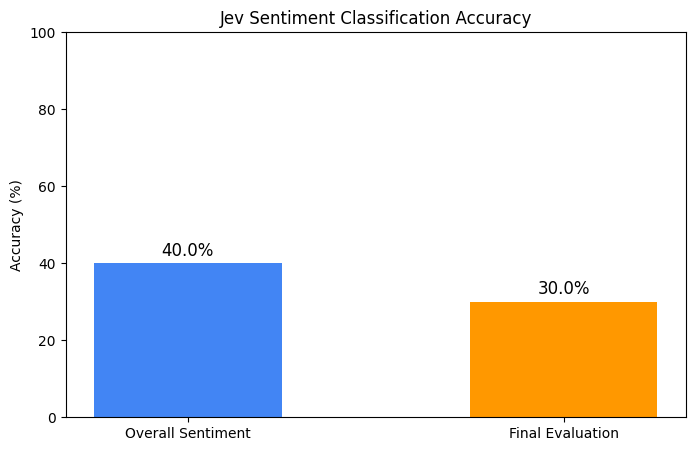

===== 정확도 비교 결과 =====
전체 감성 기준: 40.0%
최종 평가 기준: 30.0%


In [ ]:

# 감성 분류 정확도 시각화

import matplotlib.pyplot as plt

methods = ["Overall Sentiment", "Final Evaluation"]
accuracies = [overall_accuracy, final_accuracy]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    methods,
    accuracies,
    color=["#4285F4", "#FF9800"],
    width=0.5
)

plt.title("Jev Sentiment Classification Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{accuracy:.1f}%",
        ha="center",
        fontsize=12
    )

plt.show()

print("===== 정확도 비교 결과 =====")
print(f"전체 감성 기준: {overall_accuracy:.1f}%")
print(f"최종 평가 기준: {final_accuracy:.1f}%")


In [ ]:

# Jev 감성 분류 오류 사례 분석

# 전체 감성 기준에서 잘못 분류한 리뷰 추출
error_df = df[
    df["전체 감성 정답 여부"] == False
].copy()

print("===== Jev 감성 분류 오류 분석 =====")
print("전체 리뷰 수:", len(df))
print("오류 리뷰 수:", len(error_df))

if len(error_df) > 0:
    print("\n===== 잘못 분류된 리뷰 =====")

    for _, row in error_df.iterrows():
        print(f"\n리뷰 번호: {row['번호']}")
        print(f"리뷰 내용: {row['리뷰']}")
        print(f"사람 기준 정답: {row['사람 기준 정답']}")
        print(f"Jev 판단 결과: {row['전체 감성']}")
        print("-" * 40)

display(error_df[[
    "번호",
    "리뷰",
    "사람 기준 정답",
    "전체 감성"
]])


===== Jev 감성 분류 오류 분석 =====
전체 리뷰 수: 10
오류 리뷰 수: 6

===== 잘못 분류된 리뷰 =====

리뷰 번호: 4
리뷰 내용: 직원은 친절했지만 매장이 너무 시끄러웠어요.
사람 기준 정답: 중립
Jev 판단 결과: 긍정
----------------------------------------

리뷰 번호: 5
리뷰 내용: 디자인은 예쁘지만 사용하기 불편해요.
사람 기준 정답: 부정
Jev 판단 결과: 중립
----------------------------------------

리뷰 번호: 6
리뷰 내용: 맛도 좋고 서비스도 정말 만족스러웠어요.
사람 기준 정답: 긍정
Jev 판단 결과: 중립
----------------------------------------

리뷰 번호: 7
리뷰 내용: 가격도 비싸고 품질도 좋지 않았어요.
사람 기준 정답: 부정
Jev 판단 결과: 중립
----------------------------------------

리뷰 번호: 9
리뷰 내용: 시설은 깨끗했지만 위치가 너무 멀었어요.
사람 기준 정답: 중립
Jev 판단 결과: 긍정
----------------------------------------

리뷰 번호: 10
리뷰 내용: 기대보다 별로였지만 직원들은 친절했어요.
사람 기준 정답: 중립
Jev 판단 결과: 부정
----------------------------------------


,번호,리뷰,사람 기준 정답,전체 감성
3,4,직원은 친절했지만 매장이 너무 시끄러웠어요.,중립,긍정
4,5,디자인은 예쁘지만 사용하기 불편해요.,부정,중립
5,6,맛도 좋고 서비스도 정말 만족스러웠어요.,긍정,중립
6,7,가격도 비싸고 품질도 좋지 않았어요.,부정,중립
8,9,시설은 깨끗했지만 위치가 너무 멀었어요.,중립,긍정
9,10,기대보다 별로였지만 직원들은 친절했어요.,중립,부정


In [ ]:

# Jev 감성 분류 판단 기준 개선 실험

improved_questions = {
    "sentiment": {
        "type": "choice",
        "instructions": (
            "한국어 고객 리뷰의 전체 감성을 분류하세요. "
            "긍정 표현과 부정 표현을 모두 고려하세요. "
            "'하지만', '그러나', '-지만' 등의 역접 표현을 주의 깊게 살펴보세요. "
            "단순히 마지막 문장만 보지 말고 전체 평가를 판단하세요."
        ),
        "criteria": {
            "positive": (
                "전체적으로 만족하거나 긍정적인 평가가 우세함"
            ),
            "negative": (
                "전체적으로 불만족하거나 부정적인 평가가 우세함"
            ),
            "neutral": (
                "긍정과 부정이 비슷하게 나타나거나 "
                "명확한 감성을 판단하기 어려움"
            )
        }
    }
}

improved_results = []

for review in reviews:
    result = jev.decide(review, improved_questions)
    answer = result["answers"]["sentiment"]

    improved_results.append(
        labels.get(answer["choice"], answer["choice"])
    )

# 기존 결과와 개선 결과 비교
df["개선 후 감성"] = improved_results

df["개선 후 정답 여부"] = (
    df["개선 후 감성"] == df["사람 기준 정답"]
)

improved_accuracy = df["개선 후 정답 여부"].mean() * 100

print("===== 판단 기준 개선 전후 비교 =====")
print(f"개선 전 정확도: {overall_accuracy:.1f}%")
print(f"개선 후 정확도: {improved_accuracy:.1f}%")
print(f"정확도 변화: {improved_accuracy - overall_accuracy:+.1f}%p")

display(df[[
    "번호",
    "리뷰",
    "사람 기준 정답",
    "전체 감성",
    "개선 후 감성",
    "개선 후 정답 여부"
]])


===== 판단 기준 개선 전후 비교 =====
개선 전 정확도: 40.0%
개선 후 정확도: 20.0%
정확도 변화: -20.0%p


,번호,리뷰,사람 기준 정답,전체 감성,개선 후 감성,개선 후 정답 여부
0,1,음식은 맛있었지만 서비스가 너무 느렸어요.,중립,중립,부정,False
1,2,가격은 비싸지만 품질은 정말 좋아요.,긍정,긍정,긍정,True
2,3,배송은 빨랐지만 제품이 파손되어 있었어요.,부정,부정,긍정,False
3,4,직원은 친절했지만 매장이 너무 시끄러웠어요.,중립,긍정,긍정,False
4,5,디자인은 예쁘지만 사용하기 불편해요.,부정,중립,긍정,False
5,6,맛도 좋고 서비스도 정말 만족스러웠어요.,긍정,중립,긍정,True
6,7,가격도 비싸고 품질도 좋지 않았어요.,부정,중립,긍정,False
7,8,배송은 느렸지만 포장이 아주 꼼꼼했어요.,중립,중립,긍정,False
8,9,시설은 깨끗했지만 위치가 너무 멀었어요.,중립,긍정,부정,False
9,10,기대보다 별로였지만 직원들은 친절했어요.,중립,부정,긍정,False


In [5]:
reviews = [
    "음식은 맛있었지만 서비스가 너무 느렸어요.",
    "가격은 비싸지만 품질은 정말 좋아요.",
    "배송은 빨랐지만 제품이 파손되어 있었어요.",
    "직원은 친절했지만 매장이 너무 시끄러웠어요.",
    "디자인은 예쁘지만 사용하기 불편해요.",
    "맛도 좋고 서비스도 정말 만족스러웠어요.",
    "가격도 비싸고 품질도 좋지 않았어요.",
    "배송은 느렸지만 포장이 아주 꼼꼼했어요.",
    "시설은 깨끗했지만 위치가 너무 멀었어요.",
    "기대보다 별로였지만 직원들은 친절했어요."
]

print("리뷰 데이터 준비 완료:", len(reviews))

리뷰 데이터 준비 완료: 10


In [ ]:

# 한국어 원문과 영어 번역문 비교 실험

english_reviews = [
    "The food was delicious, but the service was too slow.",
    "The price was high, but the quality was really good.",
    "Delivery was fast, but the product was damaged.",
    "The staff were friendly, but the store was too noisy.",
    "The design was pretty, but it was inconvenient to use.",
    "The food was good and the service was very satisfying.",
    "The price was high and the quality was poor.",
    "Delivery was slow, but the packaging was very careful.",
    "The facilities were clean, but the location was too far.",
    "It was worse than expected, but the staff were friendly."
]

english_results = []

# 한국어 실험과 동일한 판단 기준 사용
for review in english_reviews:
    result = jev.decide(review, comparison_questions)

    answer = result["answers"]["overall"]

    english_results.append(
        labels.get(answer["choice"], answer["choice"])
    )

df["영어 번역 감성"] = english_results

df["영어 번역 정답 여부"] = (
    df["영어 번역 감성"] == df["사람 기준 정답"]
)

english_accuracy = df["영어 번역 정답 여부"].mean() * 100

print("===== 한국어와 영어 감성 분류 비교 =====")
print(f"한국어 원문 정확도: {overall_accuracy:.1f}%")
print(f"영어 번역 정확도: {english_accuracy:.1f}%")

display(df[[
    "번호",
    "사람 기준 정답",
    "전체 감성",
    "영어 번역 감성",
    "영어 번역 정답 여부"
]])


===== 한국어와 영어 감성 분류 비교 =====
한국어 원문 정확도: 40.0%
영어 번역 정확도: 70.0%


,번호,사람 기준 정답,전체 감성,영어 번역 감성,영어 번역 정답 여부
0,1,중립,중립,부정,False
1,2,긍정,긍정,긍정,True
2,3,부정,부정,부정,True
3,4,중립,긍정,부정,False
4,5,부정,중립,부정,True
5,6,긍정,중립,긍정,True
6,7,부정,중립,부정,True
7,8,중립,중립,중립,True
8,9,중립,긍정,부정,False
9,10,중립,부정,중립,True


In [1]:

# Jev 감성 분류 실험 결과 종합 비교

import matplotlib.pyplot as plt

experiment_names = [
    "Korean Original",
    "Korean Improved",
    "English Translation"
]

experiment_scores = [
    overall_accuracy,
    improved_accuracy,
    english_accuracy
]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    experiment_names,
    experiment_scores,
    color=["#4285F4", "#FF9800", "#34A853"],
    width=0.55
)

plt.title("Jev Sentiment Classification Experiment Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, score in zip(bars, experiment_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 2,
        f"{score:.1f}%",
        ha="center",
        fontsize=12
    )

plt.tight_layout()
plt.savefig("jev_experiment_comparison.png", dpi=300)
plt.show()

print("===== 실험 결과 종합 =====")
for name, score in zip(experiment_names, experiment_scores):
    print(f"{name}: {score:.1f}%")

print("그래프 저장 완료: jev_experiment_comparison.png")


NameError: name 'overall_accuracy' is not defined

## 3. 첫 번째 판단 — `noul` (예/아니오)

가장 단순한 질문부터 해봅시다. `jev.decide(state, questions)` 한 줄이 전부입니다.
질문은 `{"이름": {"type": ..., "instructions": ...}}` 형태의 dict이고, 답도 같은 이름으로 돌아옵니다.

In [ ]:
import json

result = jev.decide(
    {"age": 17},
    {"adult": {"type": "noul", "instructions": "Is this person an adult (18 or older)?"}},
)
print(json.dumps(result, indent=2))

{
  "answers": {
    "adult": {
      "type": "noul",
      "probabilities": {
        "false": 0.9168,
        "true": 0.0832
      },
      "confidence": 0.9168,
      "answer_confidence": 0.9168,
      "noul": 0.0832,
      "action": {
        "act_probability": 1.0
      }
    }
  }
}


결과는 `True/False`가 아니라 **'예'일 확률**(`noul`)입니다. 17살이니 낮게 나와야 정상입니다.

- `probabilities`: `true`/`false` 각각의 확률
- `confidence`: 더 높은 쪽의 확률 (= 모델이 얼마나 확신하는지)

💡 공식 Jev의 Noul은 `confidence` 필드 없이 확률 하나만 돌려줍니다. 예/아니오 질문에서는 *확률 자체가 확신도*이기 때문입니다.
0.5에 가까울수록 "모르겠다", 0이나 1에 가까울수록 확신입니다. OpenJevX는 편의상 `confidence`도 함께 줍니다.

앞으로 쓰기 편하게 결과를 한 줄로 보여주는 작은 함수를 만들어 둡니다.

In [ ]:
def show(answers):
    """decide() 결과의 answers를 사람이 읽기 좋게 출력"""
    for name, a in answers.items():
        if a["type"] == "noul":
            main = f"noul={a['noul']:.2f}"
        elif a["type"] == "choice":
            main = f"choice={a['choice']}"
        else:
            main = f"score={a['score']:.2f}"
        probs = {k: round(v, 2) for k, v in a["probabilities"].items()}
        print(f"[{name}] {main}  (confidence {a['confidence']:.2f})  {probs}")

## 4. 규칙 판단 — JSON state 넣기

state에는 문자열뿐 아니라 **JSON(dict)** 을 넣을 수 있습니다. 주문, 영업시간, 측정값처럼 구조화된 데이터를 판단할 때 씁니다.

⚠️ 요령이 하나 있습니다. **판단 기준(규칙)을 state나 질문 안에 써 주세요.** 모델이 "무료배송 기준이 얼마인지" 같은 걸 알 수는 없습니다.

In [ ]:
CASES = [
    ({"cart_total": 72.5, "rule": "Free shipping when the cart total is 50 or more."}, "Does this order get free shipping?"),
    ({"cart_total": 32.0, "rule": "Free shipping when the cart total is 50 or more."}, "Does this order get free shipping?"),
    ({"opening_hours": "09:00-18:00", "now": "14:10"}, "Is the store open now?"),
    ({"opening_hours": "09:00-18:00", "now": "19:30"}, "Is the store open now?"),
    ({"temperature_c": 38.6}, "Does this person have a fever (38.0 C or higher)?"),
    ({"bag_weight_kg": 19, "limit_kg": 23}, "Is the bag over the weight limit?"),
]

for state, q in CASES:
    a = jev.decide(state, {"q": {"type": "noul", "instructions": q}})["answers"]["q"]
    verdict = "YES" if a["noul"] >= 0.5 else "no "
    print(f"{verdict}  p={a['noul']:.2f}  {state}  ← {q}")

YES  p=0.90  {'cart_total': 72.5, 'rule': 'Free shipping when the cart total is 50 or more.'}  ← Does this order get free shipping?
no   p=0.09  {'cart_total': 32.0, 'rule': 'Free shipping when the cart total is 50 or more.'}  ← Does this order get free shipping?
YES  p=0.90  {'opening_hours': '09:00-18:00', 'now': '14:10'}  ← Is the store open now?
no   p=0.08  {'opening_hours': '09:00-18:00', 'now': '19:30'}  ← Is the store open now?
YES  p=0.90  {'temperature_c': 38.6}  ← Does this person have a fever (38.0 C or higher)?
no   p=0.09  {'bag_weight_kg': 19, 'limit_kg': 23}  ← Is the bag over the weight limit?


## 5. 세 가지 질문을 한 번에

고객 문의 하나에 **부서(`choice`) · 환불 여부(`noul`) · 긴급도(`score`)** 를 동시에 묻습니다.
프롬프트도, "JSON으로만 답하세요" 같은 지시도, 파싱 코드도 없습니다. 출력 형식은 요청 구조가 정합니다.

- `choice`의 `criteria`는 *모델에게 하는 부탁*이 아니라 **후보의 정의**입니다 (`후보 이름: 설명`).
- `score`의 `criteria`는 0단계부터 순서대로 나열한 **단계 설명 리스트**입니다.

In [ ]:
QUESTIONS = {
    "department": {
        "type": "choice",
        "instructions": "Which team should handle this ticket?",
        "criteria": {
            "billing":   "payments, charges, refunds, invoices",
            "technical": "errors, outages, how-to, integration",
            "sales":     "purchase, quotes, pricing plans",
            "other":     "none of the above",
        },
    },
    "refund": {
        "type": "noul",
        "instructions": "Is the customer asking for a refund or payment cancellation?",
    },
    "urgency": {
        "type": "score",
        "instructions": "How urgent is this?",
        "criteria": ["not urgent", "normal", "urgent", "very urgent"],
    },
}

result = jev.decide("I was charged twice. Please refund me quickly.", QUESTIONS)
show(result["answers"])

[department] choice=billing  (confidence 0.95)  {'billing': 0.95, 'technical': 0.02, 'sales': 0.01, 'other': 0.02}
[refund] noul=0.90  (confidence 0.90)  {'false': 0.1, 'true': 0.9}
[urgency] score=2.88  (confidence 0.92)  {'0': 0.01, '1': 0.01, '2': 0.06, '3': 0.92}


## 6. 결과 읽는 법

### score는 정수가 아니라 *기대값*
`urgency`가 `2.88`처럼 정수가 아닌 값으로 나옵니다. 우리가 정의한 단계는 0~3의 정수인데 말이죠.
이는 각 단계 확률로 가중 평균한 값입니다. 예를 들어 `2 × 0.06 + 3 × 0.92 ≈ 2.88` → "거의 확실히 *very urgent*".
직접 확인해 봅시다.

In [ ]:
urg = result["answers"]["urgency"]
levels = QUESTIONS["urgency"]["criteria"]

expected = sum(int(level) * p for level, p in urg["probabilities"].items())
best = max(urg["probabilities"], key=urg["probabilities"].get)

print(f"직접 계산한 기대값: {expected:.3f}  /  모델이 준 score: {urg['score']:.3f}")
print(f"가장 가능성 높은 단계: {best} = {levels[int(best)]!r}")

직접 계산한 기대값: 2.881  /  모델이 준 score: 2.881
가장 가능성 높은 단계: 3 = 'very urgent'


### confidence는 언제 쓸모가 있나
쉬운 문의에서는 confidence가 높게 나옵니다. 의미가 생기는 건 **애매한 문의**입니다.
여러 문의를 돌려서 confidence가 어떻게 달라지는지 봅시다.

> Colab 무료 CPU에서는 질문 3개짜리 문의 하나에 몇 초 걸립니다(질문이 많고 입력이 길수록 느려짐). 아래 셀은 30초 안팎 걸립니다.

In [ ]:
import time
import pandas as pd

TICKETS = [
    "I was charged twice. Please refund me quickly.",
    "Just wanted to say I love the service. Thanks!",
    "The API example returns a 401 error. Where should I look?",
    "We have a team of 20. Can I get a quote for the enterprise plan?",
    "I ordered yesterday and it hasn't even shipped yet. When will it arrive?",
    "Cancel my subscription right now and refund everything or I'm reporting you.",
]

rows = []
for text in TICKETS:
    t0 = time.perf_counter()
    a = jev.decide(text, QUESTIONS)["answers"]
    ms = (time.perf_counter() - t0) * 1000
    d, r, u = a["department"], a["refund"], a["urgency"]
    rows.append({
        "ticket": text[:45] + ("…" if len(text) > 45 else ""),
        "dept": d["choice"], "dept conf": round(d["confidence"], 2),
        "refund p": round(r["noul"], 2),
        "urgency": round(u["score"], 2), "urg conf": round(u["confidence"], 2),
        "ms": round(ms),
    })

df = pd.DataFrame(rows)
df

,ticket,dept,dept conf,refund p,urgency,urg conf,ms
0,I was charged twice. Please refund me quickly…,billing,0.95,0.90,2.88,0.92,6174
1,Just wanted to say I love the service. Thanks…,other,0.90,0.09,0.26,0.79,4553
2,The API example returns a 401 error. Where sh…,technical,0.95,0.13,2.25,0.51,4584
3,We have a team of 20. Can I get a quote for t…,sales,0.89,0.09,0.44,0.63,6213
4,I ordered yesterday and it hasn't even shippe…,other,0.54,0.10,1.19,0.41,4817
5,Cancel my subscription right now and refund e…,billing,0.95,0.90,2.88,0.92,5649


**관찰 포인트**
- **배송 문의**는 네 후보(billing/technical/sales/other) 어디에도 깔끔히 들어가지 않습니다. `other`로 가더라도 confidence가 뚝 떨어집니다. 이건 후보 정의가 부족하다는 신호입니다 (`shipping` 후보 추가 고려).
- **401 에러 문의**의 긴급도처럼 사람이 봐도 애매한 판단은 confidence가 낮게(0.5 근처) 나옵니다.
- LLM은 같은 답을 내도 "확신해서인지, 어쩔 수 없이 고른 건지" 알려주지 않습니다. 판단 모델은 그 정보를 **한 번의 호출에** 함께 줍니다.

## 7. 알아둘 한계 — 한국어 입력

OpenJevX는 주로 **영어 데이터로 학습**되었습니다. 같은 내용을 한국어로 넣으면 어떻게 될까요?

In [ ]:
PAIRS = [
    ("I was charged twice. Please refund me quickly.",
     "결제가 두 번 됐습니다. 빨리 환불해주세요."),
    ("We have a team of 20. Can I get a quote for the enterprise plan?",
     "팀 20명이 쓸 건데 엔터프라이즈 요금제 견적 받을 수 있을까요?"),
]

for en, ko in PAIRS:
    for lang, text in [("EN", en), ("KO", ko)]:
        a = jev.decide(text, QUESTIONS)["answers"]
        d, r = a["department"], a["refund"]
        print(f"{lang} | dept={d['choice']:9s} conf={d['confidence']:.2f} | refund p={r['noul']:.2f} | {text}")
    print()

EN | dept=billing   conf=0.95 | refund p=0.90 | I was charged twice. Please refund me quickly.
KO | dept=other     conf=0.37 | refund p=0.11 | 결제가 두 번 됐습니다. 빨리 환불해주세요.

EN | dept=sales     conf=0.89 | refund p=0.09 | We have a team of 20. Can I get a quote for the enterprise plan?
KO | dept=other     conf=0.61 | refund p=0.12 | 팀 20명이 쓸 건데 엔터프라이즈 요금제 견적 받을 수 있을까요?



영어로는 정확하고 확신 있게 답하지만, 한국어로는 엉뚱한 부서를 고르거나 확신이 크게 떨어집니다.
특히 *"빨리 환불해주세요"* 에 환불 확률을 낮게 주는 것처럼 **틀린 답을 그럴듯한 확신으로** 내는 경우도 있습니다.

교훈은 두 가지입니다.
1. **모델이 학습한 분포 안에서 쓰기**: 한국어 서비스라면 입력을 영어로 번역해 넣거나, 한국어 데이터로 파인튜닝(저장소의 `finetuning/` 참고)해야 합니다.
2. **confidence만 믿지 말고 평가셋으로 확인하기**: 내 데이터 수십 건에 정답을 달아 직접 재보는 것이 가장 확실합니다. (위키독스 9부 "Jev를 제대로 평가하기")

## 8. 실습: AI는 판단하고, 코드는 통제한다

모델의 확률을 그대로 `if` 문에 넣으면 *똑똑한 조건문(Smart If)* 이 됩니다.
confidence가 충분히 높으면 자동 처리하고, 낮으면 사람에게 넘기는 **Confidence Gated Routing**을 만들어 봅시다.
임계값(0.8, 0.85 등)은 실제 데이터로 조정하는 값입니다.

In [ ]:
CONF_THRESHOLD = 0.80     # 부서 판단 confidence가 이보다 낮으면 사람 검토
REFUND_THRESHOLD = 0.85   # 환불 플로우 자동 시작 기준


def route(ticket: str) -> str:
    a = jev.decide(ticket, QUESTIONS)["answers"]
    dept, refund, urgency = a["department"], a["refund"]["noul"], a["urgency"]["score"]

    if dept["confidence"] < CONF_THRESHOLD:
        return f"🙋 사람 검토 (부서 판단이 애매함: {dept['choice']} {dept['confidence']:.2f})"

    actions = [f"📨 {dept['choice']} 팀으로 전달"]
    if refund > REFUND_THRESHOLD:
        actions.append("💸 환불 플로우 시작")
    if urgency >= 2.5:
        actions.append("🚨 우선순위 상향")
    return " + ".join(actions)


for t in TICKETS:
    print(f"- {t}\n    → {route(t)}")

- I was charged twice. Please refund me quickly.
    → 📨 billing 팀으로 전달 + 💸 환불 플로우 시작 + 🚨 우선순위 상향
- Just wanted to say I love the service. Thanks!
    → 📨 other 팀으로 전달
- The API example returns a 401 error. Where should I look?
    → 📨 technical 팀으로 전달
- We have a team of 20. Can I get a quote for the enterprise plan?
    → 📨 sales 팀으로 전달
- I ordered yesterday and it hasn't even shipped yet. When will it arrive?
    → 🙋 사람 검토 (부서 판단이 애매함: other 0.54)
- Cancel my subscription right now and refund everything or I'm reporting you.
    → 📨 billing 팀으로 전달 + 💸 환불 플로우 시작 + 🚨 우선순위 상향


## 9. 정리

| 기억할 것 | 내용 |
|---|---|
| Jev는 무엇? | 생성하지 않고 **판단**하는 System One Model |
| OpenJevX | 같은 요청 형식을 따르는 오픈 가중치 판단 모델. CPU·로컬에서 동작, API 키 불필요 |
| 호출 형태 | `jev.decide(state, {이름: {"type": ..., "instructions": ..., "criteria": ...}})` |
| 질문 세 가지 | `choice`(후보 중 하나) · `noul`(예/아니오 확률) · `score`(정도, 기대값) |
| 핵심 가치 | 답과 함께 오는 **확률과 confidence**. 이걸 버리면 판단 모델을 쓰는 이유의 절반을 버리는 것 |
| 실무 패턴 | 높은 confidence는 자동 처리, 낮은 건 사람/LLM(System 2)에게 넘기기 |
| 주의 | 규칙은 state/질문에 명시, 영어 입력 권장, 내 데이터로 정확도 직접 확인 |

### 더 해볼 것
- 여러분 서비스에서 **답이 정해진 후보 중 하나인 LLM 호출**을 찾아 판단 모델로 바꿔보기
- 배송 문의를 위해 `shipping` 후보를 추가하고 confidence가 어떻게 바뀌는지 보기
- 판단 모델을 앞단 라우터로 두고, 애매한 건만 LLM에게 넘기는 Hybrid 구조 만들기 (위키독스 6부)
- 서버로 띄우기: [github.com/muthuishere/openjevx](https://github.com/muthuishere/openjevx)의 Docker 이미지는 `POST /v1/systemone` HTTP API를 제공합니다

## 부록. TypeSafe AI 공식 API로 쓰는 방식 (참고)

공식 Jev는 TypeSafe AI의 **호스팅 API**로만 쓸 수 있습니다. 이 노트북에서는 실행하지 않고 형태만 소개합니다.

- 현재 **Early Access**: TypeSafe AI 계정 생성 → Early Access 신청 → 승인 후 API 키 발급
- 설치는 `pip install typesafe-sdk`, import는 `typesafe_sdk` (하이픈 → 밑줄)
- API 키는 환경변수 `TYPESAFE_API_KEY`로 설정
- 질문을 dict 대신 `Choice` / `Noul` / `Score` 클래스로 만들고, 답은 `result.choices` / `result.nouls` / `result.scores`에서 이름으로 꺼냅니다

```python
from typesafe_sdk import TypeSafeClient, Choice, Noul, Score

with TypeSafeClient() as client:   # TYPESAFE_API_KEY 환경변수 사용
    result = client.system_one(
        state="I was charged twice. Please refund me quickly.",
        questions={
            "department": Choice(criteria={"billing": None, "technical": None, "sales": None, "other": None}),
            "refund": Noul(instructions="Is the customer asking for a refund?"),
            "urgency": Score(criteria=["not urgent", "normal", "urgent", "very urgent"]),
        },
    )
    print(result.choices["department"].choice, result.nouls["refund"].noul, result.scores["urgency"].score)
```

state + 이름 붙은 질문 → 확률이 담긴 판단이라는 구조는 OpenJevX와 같습니다. 자세한 내용은 [위키독스 2부](https://wikidocs.net/432838)를 참고하세요.

> 더 알아보기 자료: [Jev 따라하기 (위키독스)](https://wikidocs.net/432834) · [OpenJevX 모델 카드](https://huggingface.co/muthuishere/openjevx)